# Step 1 & 2: My own images + Augmentation
**Project #1 (Individual)**: Binary classification CNN, SOFIR SAKIF BIN (24930038)

My two classes are invented animals, drawn as sketchbook doodles in pen, pencil and coloured pencil on lined, grid and plain paper (20 drawings per class in `origin/`). The drawings were made with AI assistance, not by hand.

| Label | Species | Look |
|---|---|---|
| 0 | **Bloopsy** | round puffy body, two antennae with little balls, big eyes, stubby legs, smile |
| 1 | **Zigrill** | long wavy serpent, spikes along its back, horns, one eye, forked tail |

Both species use the same pens, colours and paper types, so the CNN must learn **shape**, not colour.

In [1]:
# Setup: installs any missing library the first time (safe to re-run)
import importlib, importlib.util, subprocess, sys
needed = {'tensorflow': 'tensorflow', 'cv2': 'opencv-python', 'sklearn': 'scikit-learn',
          'matplotlib': 'matplotlib', 'PIL': 'pillow'}
missing = [pkg for mod, pkg in needed.items() if importlib.util.find_spec(mod) is None]
if missing:
    print('Installing:', missing)
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
    importlib.invalidate_caches()
print('All libraries ready.')

All libraries ready.


In [2]:
from keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import os
import numpy as np

# 1. Paths (relative, so the project runs on any computer)
img_dir = 'origin'
save_dir = 'aug'
word = ['0', '1']          # 0 = Bloopsy, 1 = Zigrill

for key in word:
    os.makedirs(os.path.join(save_dir, key), exist_ok=True)

# 2. Augmentation settings: rotation, zoom, shift, flip, brightness
trainDataGen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=[0.85, 1.15],
    brightness_range=[0.7, 1.3],
    height_shift_range=0.2,
    width_shift_range=0.15,
    horizontal_flip=True,
    fill_mode='nearest'
)

# 3. Make 30 augmented copies of every original image
for img_name in word:
    target_origin_dir = os.path.join(img_dir, img_name)
    target_save_dir = os.path.join(save_dir, img_name)
    files_in_folder = [f for f in os.listdir(target_origin_dir)
                       if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    print(f"Folder '{img_name}': {len(files_in_folder)} images")

    for k, file_name in enumerate(sorted(files_in_folder)):
        img_path = os.path.join(target_origin_dir, file_name)
        img = image.load_img(img_path, target_size=(128, 128))
        img_tensor = np.expand_dims(image.img_to_array(img), axis=0)
        stem = os.path.splitext(file_name)[0]
        i = 0
        for batch in trainDataGen.flow(img_tensor, batch_size=1, seed=k,
                                       save_to_dir=target_save_dir,
                                       save_prefix=f'aug_{stem}', save_format='png'):
            i += 1
            if i >= 30:
                break
    print(f'--- Class {img_name} Done! {len(os.listdir(target_save_dir))} augmented images ---')

Folder '0': 20 images
--- Class 0 Done! 599 augmented images ---
Folder '1': 20 images
--- Class 1 Done! 599 augmented images ---


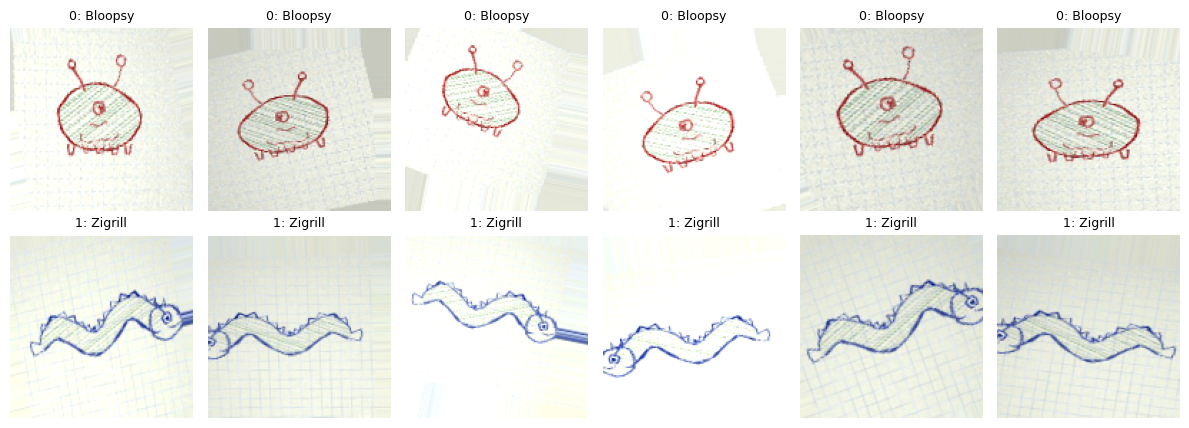

In [3]:
# Look at some augmented samples
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 6, figsize=(12, 4.4))
names = {'0': 'Bloopsy', '1': 'Zigrill'}
for r, label in enumerate(word):
    files = sorted(os.listdir(os.path.join(save_dir, label)))[:6]
    for c, f in enumerate(files):
        axes[r, c].imshow(plt.imread(os.path.join(save_dir, label, f)))
        axes[r, c].set_title(f'{label}: {names[label]}', fontsize=9)
        axes[r, c].axis('off')
plt.tight_layout()
plt.savefig('results/augmented_samples.png', dpi=100)
plt.show()